In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score, silhouette_samples, adjusted_rand_score
from sklearn.decomposition import PCA

# Show every column when we print a table
pd.set_option("display.max_columns", None)

In [2]:
#Load the dataset from a CSV file
FEATURES = ["Fresh", "Milk", "Grocery", "Frozen",
            "Detergents_Paper", "Delicassen"]
# -----------------------------------------------------------------

customers = pd.read_csv(r"C:\Akshay\Data Analytics\TPM Assignments\Machine Learning\wholesale+customers\Wholesale customers data.csv")
customers.head()

,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,2,3,12669,9656,7561,214,2674,1338
1,2,3,7057,9810,9568,1762,3293,1776
2,2,3,6353,8808,7684,2405,3516,7844
3,1,3,13265,1196,4221,6404,507,1788
4,2,3,22615,5410,7198,3915,1777,5185


In [3]:
print("Rows and columns:", customers.shape)

print("\nColumn information:")
customers.info()

print("\nMissing values per column:")
print(customers.isnull().sum())

print("\nCustomers per channel (1 = Horeca, 2 = Retail):")
print(customers["Channel"].value_counts().sort_index())

print("\nCustomers per region (1 = Lisbon, 2 = Oporto, 3 = Other):")
print(customers["Region"].value_counts().sort_index())

Rows and columns: (440, 8)

Column information:
<class 'pandas.DataFrame'>
RangeIndex: 440 entries, 0 to 439
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   Channel           440 non-null    int64
 1   Region            440 non-null    int64
 2   Fresh             440 non-null    int64
 3   Milk              440 non-null    int64
 4   Grocery           440 non-null    int64
 5   Frozen            440 non-null    int64
 6   Detergents_Paper  440 non-null    int64
 7   Delicassen        440 non-null    int64
dtypes: int64(8)
memory usage: 27.6 KB

Missing values per column:
Channel             0
Region              0
Fresh               0
Milk                0
Grocery             0
Frozen              0
Detergents_Paper    0
Delicassen          0
dtype: int64

Customers per channel (1 = Horeca, 2 = Retail):
Channel
1    298
2    142
Name: count, dtype: int64

Customers per region (1 = Lisbon, 2 = Oporto, 3 = O

In [4]:
customers[FEATURES].describe().round(0)

,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
count,440.0,440.0,440.0,440.0,440.0,440.0
mean,12000.0,5796.0,7951.0,3072.0,2881.0,1525.0
std,12647.0,7380.0,9503.0,4855.0,4768.0,2820.0
min,3.0,55.0,3.0,25.0,3.0,3.0
25%,3128.0,1533.0,2153.0,742.0,257.0,408.0
50%,8504.0,3627.0,4756.0,1526.0,816.0,966.0
75%,16934.0,7190.0,10656.0,3554.0,3922.0,1820.0
max,112151.0,73498.0,92780.0,60869.0,40827.0,47943.0


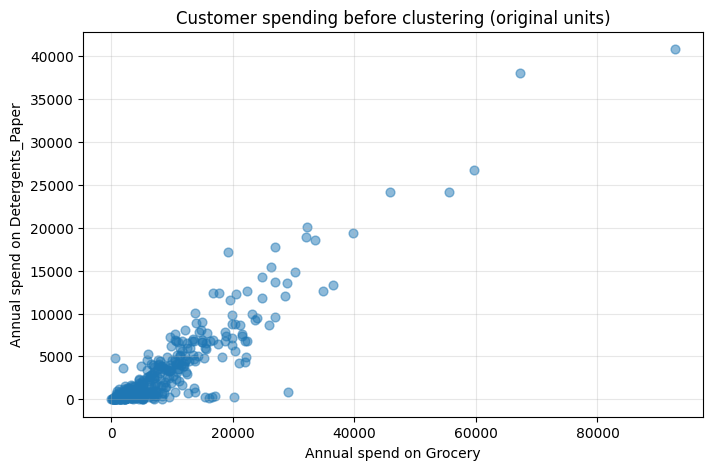

In [5]:
plt.figure(figsize=(8, 5))
plt.scatter(customers["Grocery"], customers["Detergents_Paper"], alpha=0.5, s=40)
plt.xlabel("Annual spend on Grocery")
plt.ylabel("Annual spend on Detergents_Paper")
plt.title("Customer spending before clustering (original units)")
plt.grid(True, alpha=0.3)
plt.show()

In [6]:
X = customers[FEATURES]

print("Features given to K-Means:", FEATURES)
display(X.head())

Features given to K-Means: ['Fresh', 'Milk', 'Grocery', 'Frozen', 'Detergents_Paper', 'Delicassen']


,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,12669,9656,7561,214,2674,1338
1,7057,9810,9568,1762,3293,1776
2,6353,8808,7684,2405,3516,7844
3,13265,1196,4221,6404,507,1788
4,22615,5410,7198,3915,1777,5185


,Skewness before,Skewness after log
Fresh,2.56,-1.58
Milk,4.05,-0.22
Grocery,3.59,-0.67
Frozen,5.91,-0.35
Detergents_Paper,3.63,-0.24
Delicassen,11.15,-1.09


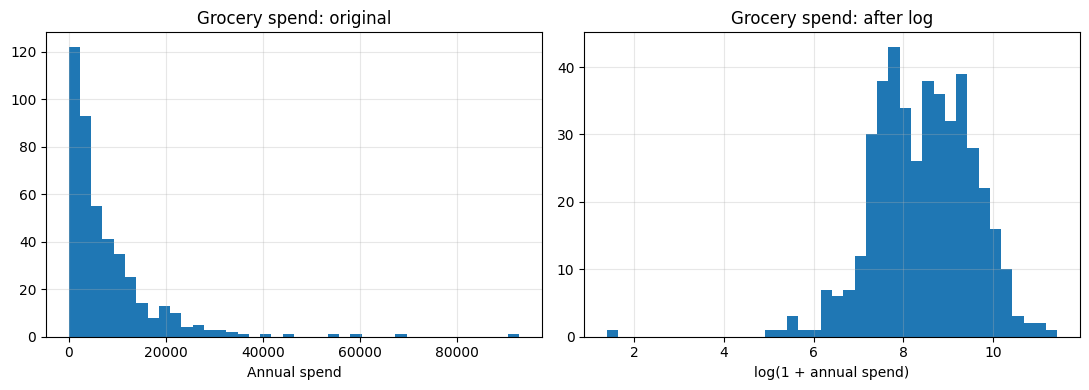

In [7]:
X_log = np.log1p(X)

skew_table = pd.DataFrame({
    "Skewness before": X.skew(),
    "Skewness after log": X_log.skew()
}).round(2)

display(skew_table)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].hist(X["Grocery"], bins=40)
axes[0].set_title("Grocery spend: original")
axes[0].set_xlabel("Annual spend")
axes[1].hist(X_log["Grocery"], bins=40)
axes[1].set_title("Grocery spend: after log")
axes[1].set_xlabel("log(1 + annual spend)")
for ax in axes:
    ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [8]:
# Scale the features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_log)

scaled_customers = pd.DataFrame(X_scaled, columns=FEATURES, index=X.index)

display(scaled_customers.head())
print("Check: average and spread of each scaled column")
display(scaled_customers.describe().loc[["mean", "std"]].round(2))

,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,0.486184,0.976299,0.440155,-1.509250,0.644143,0.408966
1,0.087889,0.990956,0.652171,0.134052,0.766043,0.627926
2,0.016356,0.891151,0.454687,0.376899,0.804405,1.776833
3,0.517477,-0.957973,-0.084792,1.141574,-0.328712,0.633133
4,0.880631,0.439662,0.395847,0.757322,0.404939,1.456588


Check: average and spread of each scaled column


,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
mean,0.0,-0.0,-0.0,0.0,-0.0,-0.0
std,1.0,1.0,1.0,1.0,1.0,1.0


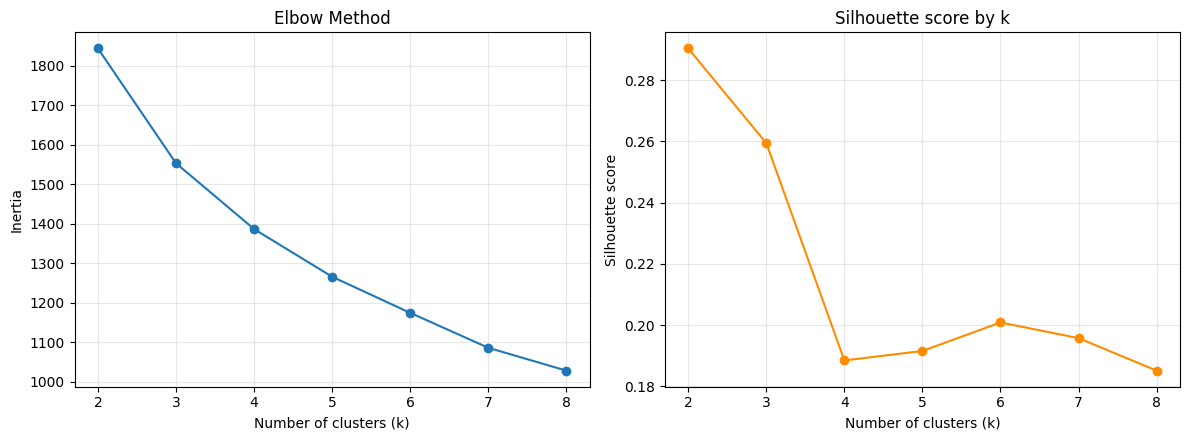

,k,inertia,silhouette
0,2,1844.064,0.290
1,3,1553.421,0.259
2,4,1386.863,0.188
3,5,1266.149,0.192
4,6,1174.759,0.201
5,7,1086.359,0.196
6,8,1028.486,0.185


In [9]:
# Find a useful number of clusters
k_values = list(range(2, 9))
inertias = []
sil_scores = []

for k in k_values:
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels_k = model.fit_predict(X_scaled)
    inertias.append(model.inertia_)
    sil_scores.append(silhouette_score(X_scaled, labels_k))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

axes[0].plot(k_values, inertias, marker="o")
axes[0].set_xlabel("Number of clusters (k)")
axes[0].set_ylabel("Inertia")
axes[0].set_title("Elbow Method")

axes[1].plot(k_values, sil_scores, marker="o", color="darkorange")
axes[1].set_xlabel("Number of clusters (k)")
axes[1].set_ylabel("Silhouette score")
axes[1].set_title("Silhouette score by k")

for ax in axes:
    ax.set_xticks(k_values)
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

pd.DataFrame({"k": k_values, "inertia": inertias, "silhouette": sil_scores}).round(3)

In [10]:
# Train the K-Means model
N_CLUSTERS = 3      # <- number of clusters to ask for

kmeans = KMeans(n_clusters=N_CLUSTERS, random_state=42, n_init=10)
kmeans.fit(X_scaled)

print(f"K-Means trained with k = {N_CLUSTERS}")
print("Cluster centres in scaled feature space:")
display(pd.DataFrame(kmeans.cluster_centers_, columns=FEATURES).round(2))

K-Means trained with k = 3
Cluster centres in scaled feature space:


,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,-1.18,0.48,0.68,-1.14,0.78,-0.70
1,0.41,0.80,0.74,0.30,0.66,0.68
2,0.16,-0.73,-0.76,0.22,-0.75,-0.21


In [11]:
# Add cluster to each customer
customers["Cluster"] = kmeans.labels_

display(customers.sort_values("Cluster").head(8))

print("Number of customers in each cluster:")
print(customers["Cluster"].value_counts().sort_index())

,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen,Cluster
439,1,3,2787,1698,2510,65,477,52,0
8,1,3,5963,3648,6192,425,1716,750,0
60,2,3,8590,3045,7854,96,4095,225,0
66,1,3,9,1534,7417,175,3468,27,0
65,2,3,85,20959,45828,36,24231,1423,0
53,2,3,491,10473,11532,744,5611,224,0
51,1,3,3347,4051,6996,239,1538,301,0
16,2,3,1020,8816,12121,134,4508,1080,0


Number of customers in each cluster:
Cluster
0     80
1    147
2    213
Name: count, dtype: int64


Share of the variation kept by the two chart axes: [0.441 0.272] = 71.3%


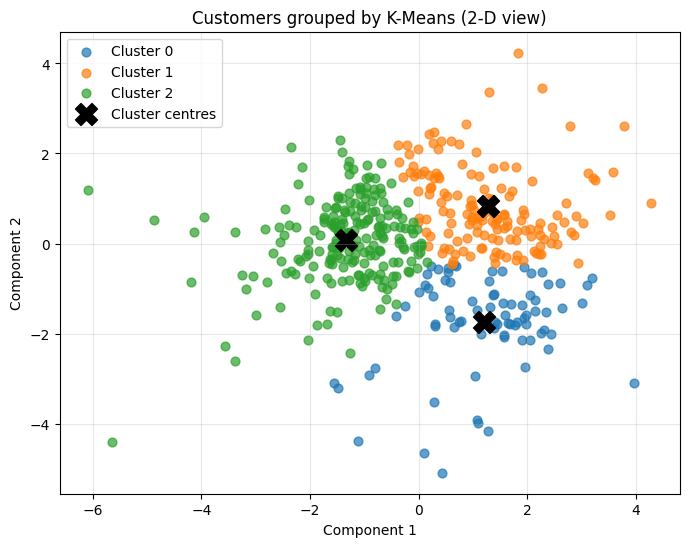

In [12]:
# Visualization
pca = PCA(n_components=2, random_state=42)
coords = pca.fit_transform(X_scaled)
centres_2d = pca.transform(kmeans.cluster_centers_)

print("Share of the variation kept by the two chart axes:",
      pca.explained_variance_ratio_.round(3), "=",
      f"{pca.explained_variance_ratio_.sum():.1%}")

plt.figure(figsize=(8, 6))
for cluster_id in sorted(customers["Cluster"].unique()):
    mask = (customers["Cluster"] == cluster_id).values
    plt.scatter(coords[mask, 0], coords[mask, 1], s=40, alpha=0.7,
                label=f"Cluster {cluster_id}")

plt.scatter(centres_2d[:, 0], centres_2d[:, 1], marker="X", s=250,
            c="black", label="Cluster centres")
plt.xlabel("Component 1")
plt.ylabel("Component 2")
plt.title("Customers grouped by K-Means (2-D view)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

Average annual spend per cluster (original units):


,Customer_Count,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
Cluster,,,,,,,
0,80,2899.0,7136.0,12570.0,607.0,5554.0,783.0
1,147,17043.0,10560.0,13334.0,4133.0,4987.0,2847.0
2,213,11939.0,2006.0,2502.0,3266.0,424.0,891.0


Spend relative to the overall average (1.0 = average):


,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
Cluster,,,,,,
0,0.24,1.23,1.58,0.20,1.93,0.51
1,1.42,1.82,1.68,1.35,1.73,1.87
2,0.99,0.35,0.31,1.06,0.15,0.58


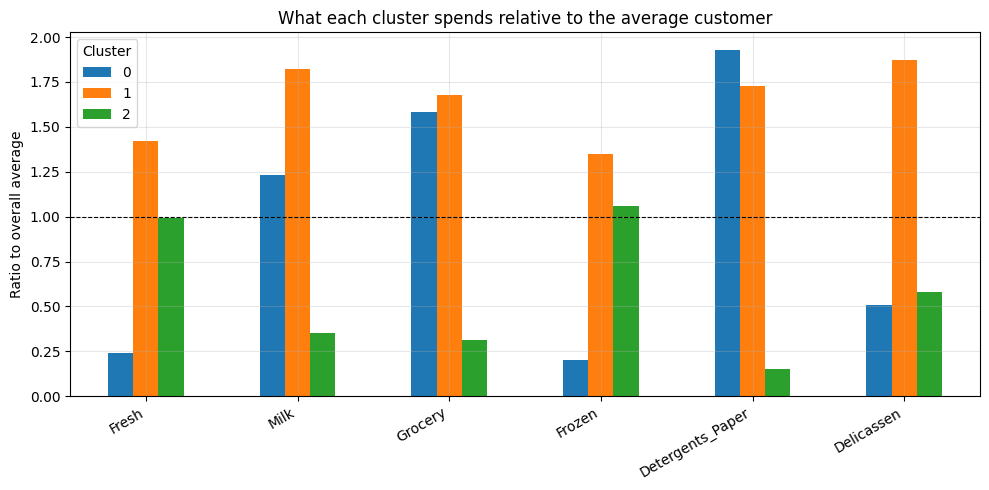

In [13]:
# Summarry of cluster 
cluster_means = customers.groupby("Cluster")[FEATURES].mean()

cluster_summary = cluster_means.round(0).copy()
cluster_summary.insert(0, "Customer_Count", customers["Cluster"].value_counts().sort_index())
print("Average annual spend per cluster (original units):")
display(cluster_summary)

relative = (cluster_means / customers[FEATURES].mean()).round(2)
print("Spend relative to the overall average (1.0 = average):")
display(relative)

relative.T.plot(kind="bar", figsize=(10, 5))
plt.axhline(1, color="black", linewidth=0.8, linestyle="--")
plt.title("What each cluster spends relative to the average customer")
plt.ylabel("Ratio to overall average")
plt.xlabel("")
plt.xticks(rotation=30, ha="right")
plt.legend(title="Cluster")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [14]:
# clusters against Channel and Region
channel_names = {1: "Horeca", 2: "Retail"}
region_names = {1: "Lisbon", 2: "Oporto", 3: "Other"}

channel_labels = customers["Channel"].map(channel_names)
region_labels = customers["Region"].map(region_names)

print("Number of customers: cluster vs channel")
display(pd.crosstab(customers["Cluster"], channel_labels))

print("Share of each cluster in each channel:")
display(pd.crosstab(customers["Cluster"], channel_labels, normalize="index").round(2))

print("Share of each cluster in each region:")
display(pd.crosstab(customers["Cluster"], region_labels, normalize="index").round(2))

Number of customers: cluster vs channel


Channel,Horeca,Retail
Cluster,,
0,32,48
1,56,91
2,210,3


Share of each cluster in each channel:


Channel,Horeca,Retail
Cluster,,
0,0.40,0.60
1,0.38,0.62
2,0.99,0.01


Share of each cluster in each region:


Region,Lisbon,Oporto,Other
Cluster,,,
0,0.18,0.12,0.70
1,0.16,0.07,0.77
2,0.19,0.12,0.69


In [15]:
# cluster quality with the silhouette score
labels = customers["Cluster"]

score = silhouette_score(X_scaled, labels)
print(f"Overall silhouette score for k={N_CLUSTERS}: {score:.3f}")

per_customer = silhouette_samples(X_scaled, labels)
per_cluster = pd.DataFrame({
    "Average silhouette": pd.Series(per_customer).groupby(labels.values).mean(),
    "Share below 0": pd.Series(per_customer < 0).groupby(labels.values).mean()
}).round(3)

print("\nSilhouette by cluster:")
display(per_cluster)

Overall silhouette score for k=3: 0.259

Silhouette by cluster:


,Average silhouette,Share below 0
0,0.121,0.250
1,0.282,0.000
2,0.296,0.014


In [16]:
# hierarchical clustering
agg = AgglomerativeClustering(n_clusters=N_CLUSTERS, linkage="ward")
agg_labels = agg.fit_predict(X_scaled)

comparison = pd.DataFrame({
    "Algorithm": ["K-Means", "Hierarchical (Ward)"],
    "Silhouette": [
        silhouette_score(X_scaled, kmeans.labels_),
        silhouette_score(X_scaled, agg_labels),
    ],
}).round(3)
display(comparison)

print("Agreement between the two methods (ARI):",
      round(adjusted_rand_score(kmeans.labels_, agg_labels), 3))

print("\nCluster sizes: K-Means rows vs Hierarchical columns")
display(pd.crosstab(customers["Cluster"], agg_labels,
                    rownames=["K-Means"], colnames=["Hierarchical"]))

,Algorithm,Silhouette
0,K-Means,0.259
1,Hierarchical (Ward),0.255


Agreement between the two methods (ARI): 0.449

Cluster sizes: K-Means rows vs Hierarchical columns


Hierarchical,0,1,2
K-Means,,,
0,10,36,34
1,50,6,91
2,202,11,0


In [17]:
# testing new customer to a cluster
new_customer = pd.DataFrame({
    "Fresh":            [9000],
    "Milk":             [8000],
    "Grocery":          [12000],
    "Frozen":           [1500],
    "Detergents_Paper": [5000],
    "Delicassen":       [1500],
})
new_customer = new_customer[FEATURES]      # same column order as training

new_scaled = scaler.transform(np.log1p(new_customer))
predicted_cluster = kmeans.predict(new_scaled)[0]

print("New customer:")
display(new_customer)
print("Assigned cluster:", predicted_cluster)

print("\nTypical spending relative to average in that cluster:")
display(relative.loc[[predicted_cluster]])

New customer:


,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,9000,8000,12000,1500,5000,1500


Assigned cluster: 1

Typical spending relative to average in that cluster:


,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
Cluster,,,,,,
1,1.42,1.82,1.68,1.35,1.73,1.87
